In [1]:
import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
DATA_URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
ZIP_PATH = "household_power_consumption.zip"
EXTRACT_DIR = "uci_power_data"

In [4]:
if not os.path.exists(ZIP_PATH):
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

In [5]:
data_file = None
for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        if file.lower() == "household_power_consumption.txt":
            data_file = os.path.join(root, file)
            break

if data_file is None:
    raise FileNotFoundError("Could not find household_power_consumption.txt in the downloaded ZIP.")

In [6]:
df = pd.read_csv(
    data_file,
    sep=";",
    na_values=["?"],
    low_memory=False
)

In [7]:
print("Original shape:", df.shape)
df.head()

Original shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [8]:
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

In [9]:
df = df.dropna(subset=["datetime"]).copy()
df["Global_active_power"] = pd.to_numeric(
    df["Global_active_power"], errors="coerce"
)

In [10]:
df = df.dropna(subset=["Global_active_power"])
df = df.set_index("datetime").sort_index()

In [11]:
hourly = df[["Global_active_power"]].resample("h").mean()
hourly = hourly.interpolate(method="time").dropna()

In [12]:
print("Hourly data shape:", hourly.shape)
print("Date range:", hourly.index.min(), "to", hourly.index.max())
hourly.head()

Hourly data shape: (34589, 1)
Date range: 2006-12-16 17:00:00 to 2010-11-26 21:00:00


,Global_active_power
datetime,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467


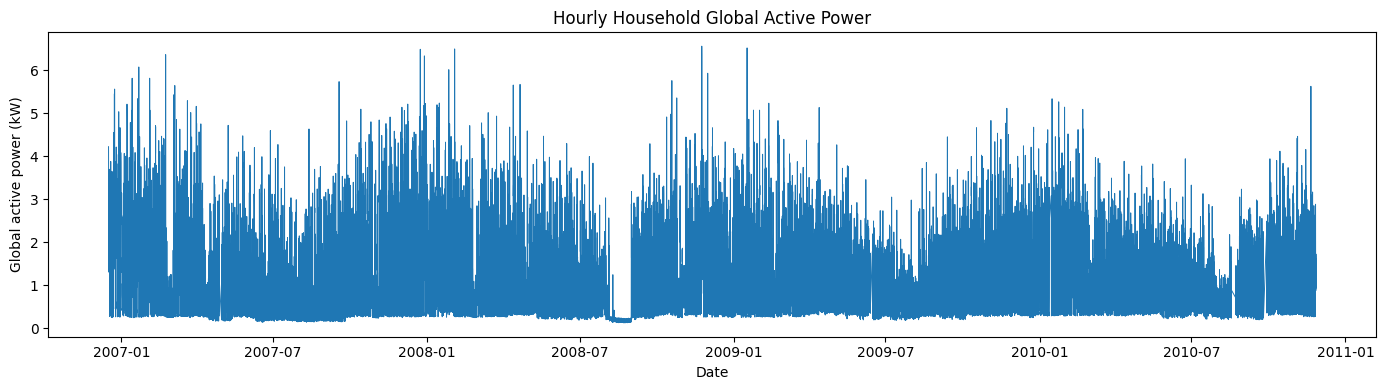

In [13]:
plt.figure(figsize=(14, 4))
plt.plot(hourly.index, hourly["Global_active_power"], linewidth=0.7)
plt.title("Hourly Household Global Active Power")
plt.xlabel("Date")
plt.ylabel("Global active power (kW)")
plt.tight_layout()
plt.show()

In [14]:
values = hourly[["Global_active_power"]].values.astype("float32")
n = len(values)

In [15]:
train_end = int(n * 0.70)
val_end = int(n * 0.85)
LOOKBACK = 24

In [16]:
scaler = MinMaxScaler()
scaler.fit(values[:train_end])
scaled_values = scaler.transform(values)

In [17]:
def make_sequences(data, start_target, end_target, lookback):
    X, y = [], []
    for i in range(max(start_target, lookback), end_target):
        X.append(data[i-lookback:i, 0])
        y.append(data[i, 0])
    X = np.asarray(X, dtype=np.float32).reshape(-1, lookback, 1)
    y = np.asarray(y, dtype=np.float32)
    return X, y

In [18]:
X_train, y_train = make_sequences(scaled_values, LOOKBACK, train_end, LOOKBACK)
X_val, y_val = make_sequences(scaled_values, train_end, val_end, LOOKBACK)
X_test, y_test = make_sequences(scaled_values, val_end, n, LOOKBACK)

In [19]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (24188, 24, 1) (24188,)
Validation: (5188, 24, 1) (5188,)
Testing: (5189, 24, 1) (5189,)


In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [21]:
def build_rnn(input_shape):
    model = Sequential([
        tf.keras.Input(shape=input_shape),
        SimpleRNN(50, activation="tanh"),
        Dropout(0.2),
        Dense(25, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

early_stop_rnn = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

In [22]:
rnn_model = build_rnn((LOOKBACK, 1))
rnn_model.summary()

history_rnn = rnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop_rnn],
    shuffle=False,
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,901 (15.24 KB)

 Trainable params: 3,901 (15.24 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0124 - mae: 0.0777 - val_loss: 0.0094 - val_mae: 0.0697
Epoch 2/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0093 - mae: 0.0678 - val_loss: 0.0094 - val_mae: 0.0691
Epoch 3/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0092 - mae: 0.0667 - val_loss: 0.0096 - val_mae: 0.0700
Epoch 4/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0090 - mae: 0.0661 - val_loss: 0.0094 - val_mae: 0.0696
Epoch 5/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0090 - mae: 0.0657 - val_loss: 0.0094 - val_mae: 0.0697
Epoch 6/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0090 - mae: 0.0657 - val_loss: 0.0093 - val_mae: 0.0684
Epoch 7/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0090 - mae: 0.0657 - val_loss: 0.0092 - val_mae: 0.0685
Epoch 8/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0089 - mae: 0.0653 - val_loss: 0.0093 - val_mae: 0.0687
Epoch 9/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - 

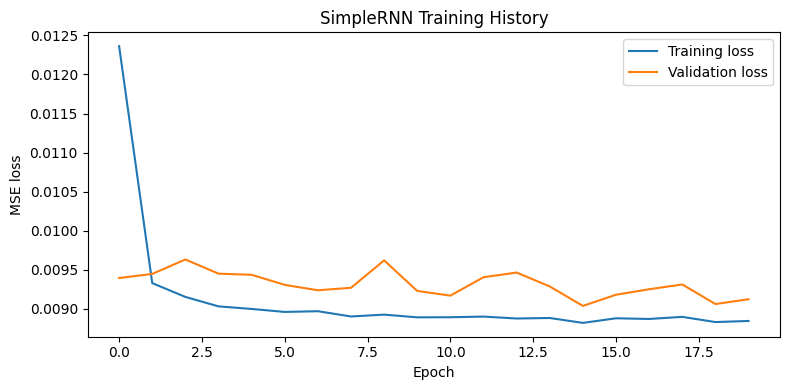

In [23]:
plt.figure(figsize=(8, 4))
plt.plot(history_rnn.history["loss"], label="Training loss")
plt.plot(history_rnn.history["val_loss"], label="Validation loss")
plt.title("SimpleRNN Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.tight_layout()

plt.show()

In [24]:
def build_lstm(input_shape):
    model = Sequential([
        tf.keras.Input(shape=input_shape),
        LSTM(50, activation="tanh"),
        Dropout(0.2),
        Dense(25, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

early_stop_lstm = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

In [25]:
lstm_model = build_lstm((LOOKBACK, 1))
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
history_lstm = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop_lstm],
    shuffle=False,
    verbose=1
)

Epoch 1/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - loss: 0.0144 - mae: 0.0880 - val_loss: 0.0104 - val_mae: 0.0753
Epoch 2/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0102 - mae: 0.0723 - val_loss: 0.0101 - val_mae: 0.0729
Epoch 3/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0098 - mae: 0.0700 - val_loss: 0.0102 - val_mae: 0.0731
Epoch 4/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.0098 - mae: 0.0696 - val_loss: 0.0102 - val_mae: 0.0732
Epoch 5/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 0.0097 - mae: 0.0692 - val_loss: 0.0102 - val_mae: 0.0728
Epoch 6/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - loss: 0.0097 - mae: 0.0691 - val_loss: 0.0102 - val_mae: 0.0726
Epoch 7/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0095 - mae: 0.0681 - val_loss: 0.0098 - val_mae: 0.0711
Epoch 8/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.0091 - mae: 0.0663 - val_loss: 0.0095 - val_mae: 0.0699
Epoch 9/30
378/378 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms

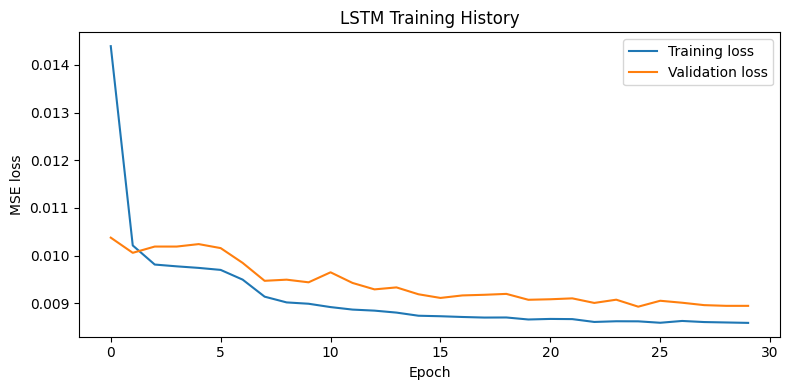

In [27]:
plt.figure(figsize=(8, 4))
plt.plot(history_lstm.history["loss"], label="Training loss")
plt.plot(history_lstm.history["val_loss"], label="Validation loss")
plt.title("LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.tight_layout()

plt.show()

In [28]:
rnn_pred_scaled = rnn_model.predict(X_test, verbose=0)
lstm_pred_scaled = lstm_model.predict(X_test, verbose=0)

In [29]:
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
rnn_pred = scaler.inverse_transform(rnn_pred_scaled).ravel()
lstm_pred = scaler.inverse_transform(lstm_pred_scaled).ravel()

In [30]:
def calculate_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

In [31]:
rnn_mae, rnn_rmse = calculate_metrics(y_test_actual, rnn_pred)
lstm_mae, lstm_rmse = calculate_metrics(y_test_actual, lstm_pred)

results = pd.DataFrame({
    "Model": ["SimpleRNN", "LSTM"],
    "MAE (kW)": [rnn_mae, lstm_mae],
    "RMSE (kW)": [rnn_rmse, lstm_rmse]
})

results

,Model,MAE (kW),RMSE (kW)
0,SimpleRNN,0.355879,0.493283
1,LSTM,0.357792,0.494127


In [32]:
plot_count = min(24 * 7, len(y_test_actual))
test_index = hourly.index[val_end:val_end + plot_count]

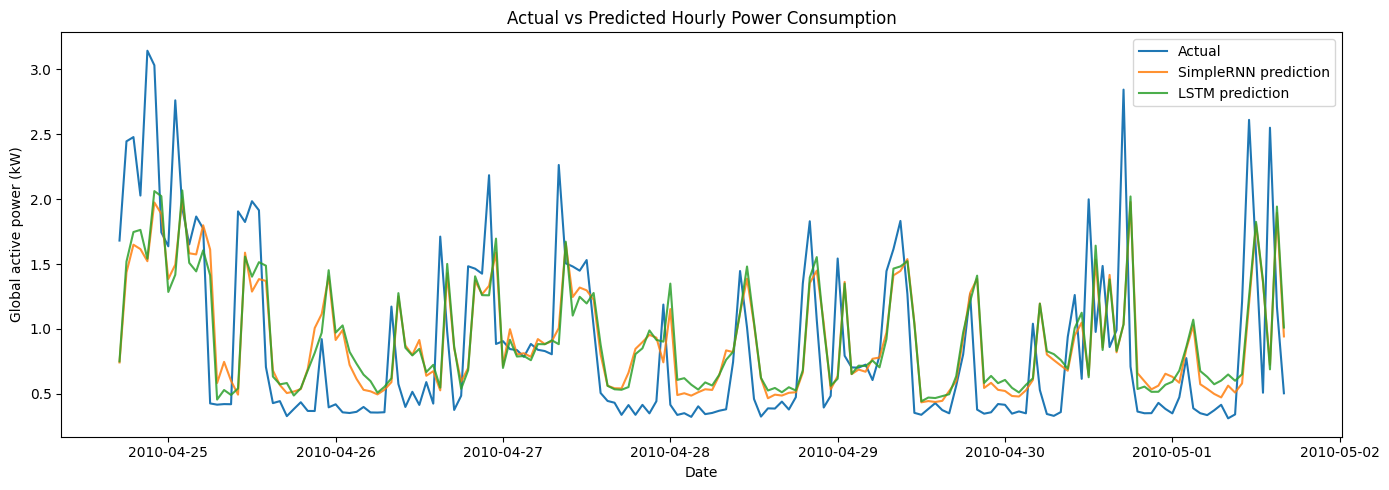

In [33]:
plt.figure(figsize=(14, 5))
plt.plot(test_index, y_test_actual[:plot_count], label="Actual", linewidth=1.5)
plt.plot(test_index, rnn_pred[:plot_count], label="SimpleRNN prediction", alpha=0.85)
plt.plot(test_index, lstm_pred[:plot_count], label="LSTM prediction", alpha=0.85)
plt.title("Actual vs Predicted Hourly Power Consumption")
plt.xlabel("Date")
plt.ylabel("Global active power (kW)")
plt.legend()
plt.tight_layout()

plt.show()

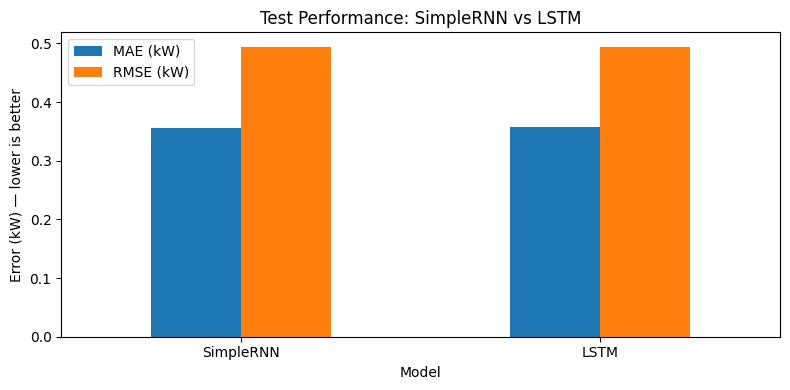

In [34]:
results.set_index("Model")[["MAE (kW)", "RMSE (kW)"]].plot(
    kind="bar", figsize=(8, 4), rot=0
)
plt.title("Test Performance: SimpleRNN vs LSTM")
plt.ylabel("Error (kW) — lower is better")
plt.tight_layout()
plt.show()

In [35]:
rnn_model.save("simple_rnn_power_forecast.keras")
lstm_model.save("lstm_power_forecast.keras")

In [36]:
prediction_results = pd.DataFrame({
    "Actual_kW": y_test_actual,
    "SimpleRNN_Predicted_kW": rnn_pred,
    "LSTM_Predicted_kW": lstm_pred
}, index=hourly.index[val_end:])

In [37]:
prediction_results.to_csv("test_predictions.csv")
results.to_csv("model_comparison_metrics.csv", index=False)

In [38]:
print("Saved: simple_rnn_power_forecast.keras")
print("Saved: lstm_power_forecast.keras")
print("Saved: test_predictions.csv")
print("Saved: model_comparison_metrics.csv")

Saved: simple_rnn_power_forecast.keras
Saved: lstm_power_forecast.keras
Saved: test_predictions.csv
Saved: model_comparison_metrics.csv
